# Where do Spurs need to recruit?

The current squad is whoever FBref lists at Tottenham in 2026-27, with the minutes they have played so far. Goalkeepers are left out. Quality comes from 2025-26, because most 2026-27 samples are only a handful of matches.

The comparison is the six Premier League clubs with the highest total squad value in 2025-26, Spurs excluded. Those clubs are worked out from the fee data. They are not typed in by hand.

## Six checks, then one score

Each outfield role is compared with the average of those six clubs.

1. **Depth.** How many players have played at least a quarter of the minutes available so far this season. A quarter of a nine-game season is about 200 minutes, not a quarter of 38 games.
2. **Quality.** The model's predicted fee for the two players with the most minutes in the role, averaged. This is what the 2025-26 stats imply, not what the market says. A player needs 900 minutes in 2025-26 to have a prediction. If one of the top two does not, the average uses the one who does, and the table says so.
3. **Output profile.** Four per-90 numbers that describe the role. Spurs' average is weighted by 2026-27 minutes and placed as a percentile among the benchmark players in that role. The rates themselves are from 2025-26, and only from seasons of 900 minutes or more. A percentile of 50 is the middle of that group.
4. **Age.** The share of the role's minutes played by someone aged 30 or older.
5. **Contract.** The share of minutes played by someone whose Transfermarkt contract expires by 30 June 2027. Players with no date on file are left out of both the numerator and the denominator. This file is a July 2026 snapshot, not a live list of deals.
6. **Style.** Which of the 2025-26 style clusters has nobody at Spurs in that role. Style does not go into the score. It says what kind of player would fill the hole.

The need score z-scores each of the first five gaps across the five roles, then adds them up. Quality is 35%, output 25%, depth 20%, age 10%, contract 10%. A bigger score means Spurs are further behind, or more exposed. The styles Spurs already have are named under the chart, so the missing one has some context.

Roles come from Transfermarkt's position. A player with no Transfermarkt match falls back to FBref, and FBref's plain "DF" becomes centre-back. Andy Robertson and Sávio are in that position: Robertson's 575 minutes sit with the centre-backs, and Sávio's 330 minutes sit with the central midfielders.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.needs import WEIGHTS, build_needs

ROLE = {"CB": "Centre-back", "FB": "Full-back", "CM": "Central midfield", "AM_W": "Wide attacker", "ST": "Striker"}
needs, squad = build_needs()
needs["role"] = needs["position_group"].map(ROLE)
clubs = needs["benchmark_clubs"].iloc[0]
display(Markdown(f"**Benchmark clubs, by 2025-26 squad value:** {clubs}."))

table = pd.DataFrame({
    "Role": needs["role"],
    "Need score": needs["need_score"].round(2),
    "Depth": needs.apply(lambda row: f"{int(row.spurs_depth)} vs {row.benchmark_depth:.1f}", axis=1),
    "Quality, €m": needs.apply(
        lambda row: f"{row.spurs_quality / 1e6:.0f} vs {row.benchmark_quality / 1e6:.0f} (n={int(row.spurs_quality_n)})",
        axis=1,
    ),
    "Output percentile": needs["output_percentile"].round(0).astype(int),
    "Age 30+ minutes": (needs["spurs_age_share"] * 100).round(0).astype(int).astype(str) + "%",
    "Contract to Jun 2027": (needs["spurs_contract_share"] * 100).round(0).astype(int).astype(str) + "%",
    "Styles already here": needs["styles_present"].fillna("none"),
    "Styles missing": needs["styles_missing"].fillna("none"),
})
display(table.style.hide(axis="index"))

Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


**Benchmark clubs, by 2025-26 squad value:** Manchester City, Arsenal, Chelsea, Liverpool, Manchester Utd, Newcastle.

Role,Need score,Depth,"Quality, €m",Output percentile,Age 30+ minutes,Contract to Jun 2027,Styles already here,Styles missing
Striker,0.910000,3 vs 1.3,37 vs 65 (n=1),9,0%,4%,Dropping forward,"Penalty-box striker, Pressing striker"
Wide attacker,0.160000,1 vs 4.2,46 vs 56 (n=1),54,0%,0%,Crossing winger,"Foul-drawing winger, Tracking winger, Inside forward"
Full-back,-0.080000,1 vs 2.7,34 vs 42 (n=2),66,0%,0%,"Attacking wing-back, Holding fullback",Defensive fullback
Central midfield,-0.480000,6 vs 3.3,41 vs 45 (n=2),48,0%,0%,"Arriving midfielder, Ball-winning destroyer, Screening midfielder, Wide midfielder",
Centre-back,-0.510000,3 vs 3.0,47 vs 32 (n=2),45,26%,3%,"Aggressive centre-back, Positional centre-back, Wide centre-back",


## The ranking

Zero is the average role. A bar to the right is a stronger case for recruiting there.

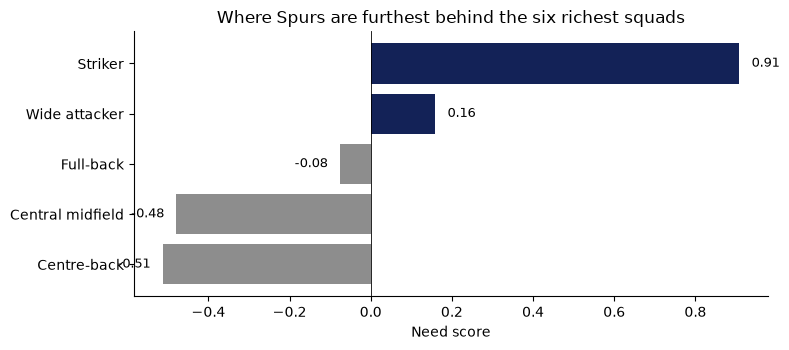

In [2]:
chart = needs.sort_values("need_score", ascending=True)
colors = ["#132257" if score > 0 else "#8d8d8d" for score in chart["need_score"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(chart["role"], chart["need_score"], color=colors)
ax.axvline(0, color="black", linewidth=0.6)
for role, score in zip(chart["role"], chart["need_score"]):
    ax.text(score + (0.03 if score >= 0 else -0.03), role, f"{score:.2f}", va="center",
            ha="left" if score >= 0 else "right", fontsize=9)
ax.set_xlabel("Need score")
ax.set_title("Where Spurs are furthest behind the six richest squads")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## Why each role ranks where it does

Each cell is a z-score. Red means that check is pushing the role up the list. Blue means Spurs are in better shape than the other roles on that check. The number in brackets under the chart is the weight.

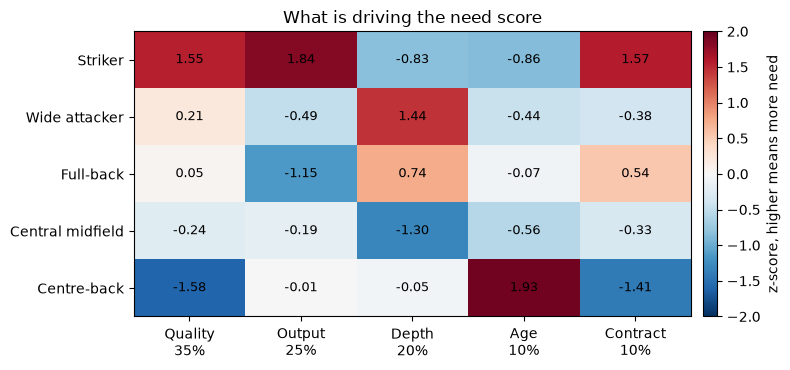

In [3]:
components = [
    ("quality", "Quality"),
    ("output", "Output"),
    ("depth", "Depth"),
    ("age", "Age"),
    ("contract", "Contract"),
]
heat = needs.set_index("role")[[f"z_{name}" for name, _ in components]]
heat.columns = [f"{label}\n{WEIGHTS[name]:.0%}" for name, label in components]
fig, ax = plt.subplots(figsize=(8, 3.8))
image = ax.imshow(heat.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        value = heat.to_numpy()[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", color="black", fontsize=9)
ax.set_title("What is driving the need score")
fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02).set_label("z-score, higher means more need")
fig.tight_layout()
plt.show()

## Verdict

**Striker — a penalty-box striker.** Solanke, Tel and Richarlison all drop deep. Nobody in the group is a penalty-box striker, and nobody is a pressing striker either. Among the benchmark strikers with a full 2025-26 season, five of eight are penalty-box strikers. The output profile is the loudest gap in the whole squad: the minute-weighted 2025-26 rates sit around the 9th percentile for shots, shots on target, goals and non-penalty goals, against only eight comparison players. The model puts Solanke near €37m. The benchmark pair averages about €65m. Marmoush has the most striker minutes this season, but he played 700 minutes in 2025-26, short of the 900-minute line, so he has no prediction and no style label. Depth is not the problem. Spurs have three strikers over the minutes bar, and the benchmark average is 1.3.

**Wide attacker — an inside forward.** Kudus is a crossing winger, and he is the only wide player over a quarter of the minutes. The benchmark average is 4.2. Spurs also have no foul-drawing winger and no tracking winger. An inside forward is the missing style the benchmark actually uses: 12 of their wide players, against 10 crossing wingers. The profile is not a crisis. Crosses are at the top of the benchmark and assists are high. Shots and shots on target are the thin part, around the 14th and 21st percentiles. Kudus is the only one of the top two with a model value, about €46m against a benchmark pair of about €56m. Kulusevski, Moore and Mudryk have no 2025-26 season in the top five leagues. Maddison's 2025-26 was 37 minutes, so it does not enter the profile.

Full-back is next, and it is not really a need on these weights. The score is slightly below average. The missing label is a defensive fullback, but Robertson's 575 minutes are filed at centre-back because he has no Transfermarkt match. Treat that third name as a data gap, not a shopping list.

Centre-back and central midfield come out as strengths. Van Hecke and van de Ven have a higher stats-implied value than the benchmark pair. Midfield has all four styles and six players over the minutes bar, against a benchmark average of 3.3. The centre-back age share, 26% against 18%, is mostly Robertson, who is 32.

## Does the top two move if the weights change?

Two checks. First, every component at 20%. Second, quality lifted to 50%, with output, depth, age and contract scaled down so they still add up to the other 50%.

In [4]:
def top_two(column):
    return list(needs.sort_values(column, ascending=False)["role"].head(2))

base = top_two("need_score")
equal = top_two("need_score_equal")
half = top_two("need_score_quality50")
lines = [
    f"Main weights: {base[0]} then {base[1]}.",
    f"Equal weights: {equal[0]} then {equal[1]}. The top two "
    + ("stay the same." if set(equal) == set(base) else "change."),
    f"Quality at 50%: {half[0]} then {half[1]}. The top two "
    + ("stay the same." if set(half) == set(base) else "change."),
]
display(Markdown("\n\n".join(lines)))
show = needs[["role", "need_score", "need_score_equal", "need_score_quality50"]].copy()
show.columns = ["Role", "Main score", "Equal weights", "Quality at 50%"]
display(show.round(2).style.hide(axis="index"))

Main weights: Striker then Wide attacker.

Equal weights: Striker then Wide attacker. The top two stay the same.

Quality at 50%: Striker then Wide attacker. The top two stay the same.

Role,Main score,Equal weights,Quality at 50%
Striker,0.910000,0.660000,1.060000
Wide attacker,0.160000,0.070000,0.170000
Full-back,-0.080000,0.020000,-0.050000
Central midfield,-0.480000,-0.520000,-0.420000
Centre-back,-0.510000,-0.220000,-0.760000


## Limitations

There is no injury data. Minutes mix fitness with the manager's choices, so a player on the bench may be a squad option the depth count ignores. The 2026-27 minutes are a partial season, about nine games, and the 25% bar is 25% of that, not of a full campaign.

Quality uses the basic per-90 stats in the value model: shots, tackles, passes of that kind, not chance quality or pressing location. A player under 900 minutes in 2025-26 has no prediction. Marmoush is the important case.

The contract shares use Transfermarkt's July 2026 snapshot. A renewal since then will not be in the file, and about a third of players in that file have no date at all. Those players are left out of the contract share rather than treated as safe or as a risk.

Robertson and Sávio have no Transfermarkt id, so the position fallback puts a full-back's minutes into centre-back and a wide player's minutes into central midfield. That makes the full-back depth look thinner than the team sheet, and it gives centre-back a "wide centre-back" it does not really have.